# 03 · Índice de expansión 3B y Top 20 — Fase 3

**Pregunta de negocio:** si 3B abre una tienda en este hexágono, ¿cuántos hogares objetivo **nuevos** gana la cadena?

El índice combina cuatro piezas:
1. **Demanda objetivo**: hogares sin auto por hexágono H3 (asignación dasimétrica desde manzanas).
2. **Competencia (Huff anidado)**: cuánta de esa demanda ya captan 3B, Neto, Bodega Aurrera, OXXO, supermercados y tienditas.
3. **Canibalización**: cuántos clientes le quitaría la tienda nueva a otras 3B.
4. **Factibilidad operativa**: 3B crece desde su red actual (94% de sus aperturas 2021–2026 cayeron a < 2.5 km de una 3B existente).

> Versión v1. Los parámetros (β, λ, radio operativo) se calibran con validación cruzada espacial en la Fase 4 (backtest).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from tesela3b import config as cfg
from tesela3b.gold import indice_h3 as ih

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
AZUL, NARANJA, GRIS, GRIS_CLARO, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#9a9893", "#e7e6e2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRIS_CLARO,
    "axes.axisbelow": True, "legend.frameon": False,
})
HALO = [pe.withStroke(linewidth=2.5, foreground="white")]

indice = gpd.read_parquet(cfg.GOLD / f"indice_h3_{cfg.CORTE_ACTUAL}.parquet").to_crs(cfg.CRS_METRIC)
top = gpd.read_parquet(cfg.GOLD / f"top{cfg.TOP_N}_{cfg.CORTE_ACTUAL}.parquet").to_crs(cfg.CRS_METRIC)
alc = gpd.read_parquet(cfg.SILVER / "alcaldias.parquet").to_crs(cfg.CRS_METRIC)
est = gpd.read_parquet(cfg.SILVER / f"establecimientos_{cfg.CORTE_ACTUAL}.parquet").to_crs(cfg.CRS_METRIC)
tiendas_3b = est[est.cadena == "3B"]
print(f"{len(indice):,} hexágonos | {len(tiendas_3b)} tiendas 3B | Top {len(top)}")

6,080 hexágonos | 305 tiendas 3B | Top 20


## 1. El mapa de oportunidad

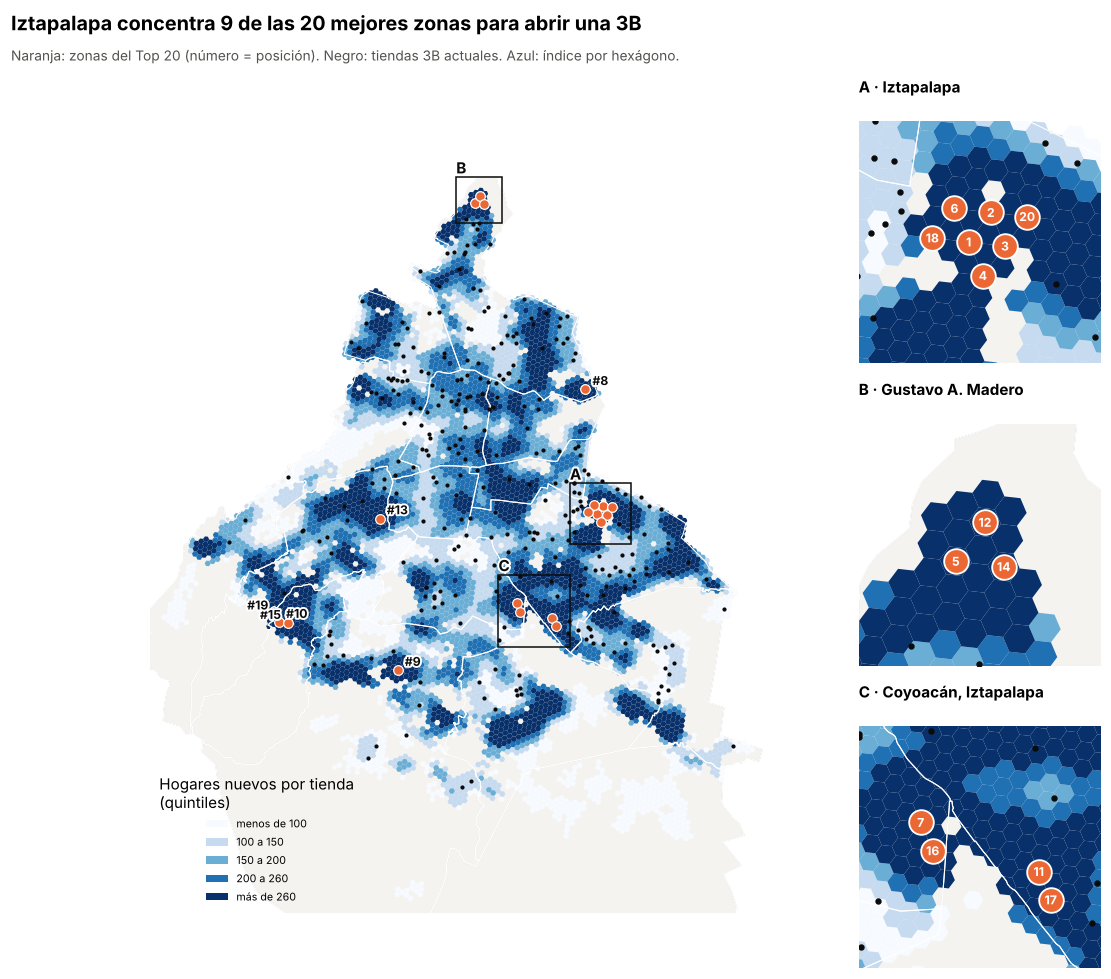

In [2]:
from matplotlib.patches import Rectangle
x0, y0, x1, y1 = indice.total_bounds
EXT = (x0 - 800, x1 + 800, y0 - 800, y1 + 800)   # recorte a la zona urbana

def base(ax, extension=EXT):
    alc.plot(ax=ax, color="#f4f3f0", edgecolor="#c9c7c0", linewidth=0.6)
    ax.set_xlim(extension[0], extension[1]); ax.set_ylim(extension[2], extension[3])
    ax.set_axis_off()

cortes = indice.indice_final.quantile([0.2, 0.4, 0.6, 0.8]).round(-1).tolist()
etiquetas = [f"menos de {cortes[0]:,.0f}"] + [f"{a:,.0f} a {b:,.0f}" for a, b in zip(cortes[:-1], cortes[1:])] + [f"más de {cortes[-1]:,.0f}"]
def capa_indice(ax, leyenda=False):
    indice.plot(ax=ax, column="indice_final", cmap="Blues", scheme="user_defined",
                classification_kwds={"bins": cortes + [indice.indice_final.max()]}, linewidth=0, legend=leyenda,
                legend_kwds={"loc": "lower left", "title": "Hogares nuevos por tienda\n(quintiles)", "labels": etiquetas, "fontsize": 7})
    alc.boundary.plot(ax=ax, color="white", linewidth=0.7)

# Zonas de acercamiento: grupos de recomendaciones alrededor de la #1 y de la mejor de GAM
c = top.geometry.centroid
def grupo(ref, radio=3000):
    cerca = c[c.distance(c.iloc[ref]) < radio]
    bx0, by0, bx1, by1 = cerca.total_bounds
    lado = max(bx1 - bx0, by1 - by0) / 2 + 1300
    cx, cy = (bx0 + bx1) / 2, (by0 + by1) / 2
    return cerca.index, (cx - lado, cx + lado, cy - lado, cy + lado)
pos = top.reset_index(drop=True)
# Acercamientos: los grupos de 3+ zonas cercanas (alrededor de la mejor de cada grupo, sin repetir)
zonas, usados = {}, set()
for i in range(len(pos)):
    if i in usados:
        continue
    idx, ext = grupo(i)
    if len(idx) >= 3:
        dentro = c[(c.x.between(ext[0], ext[1])) & (c.y.between(ext[2], ext[3]))].index   # todo lo que cae en el recuadro
        zonas[chr(65 + len(zonas))] = (dentro, ext)
        idx = dentro
        usados |= set(idx)
    if len(zonas) == 3:
        break

fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(len(zonas), 2, width_ratios=[1.6, 1], wspace=0.04, hspace=0.25)
ax = fig.add_subplot(gs[:, 0])
base(ax); capa_indice(ax, leyenda=True)
tiendas_3b.plot(ax=ax, color=TINTA, markersize=3, zorder=3)
ax.scatter(c.x, c.y, s=40, color=NARANJA, edgecolor="white", linewidth=0.8, zorder=4)
en_zona = set().union(*[set(i) for i, _ in zonas.values()])
etiquetados = []
for i, (x, y) in enumerate(zip(c.x, c.y)):
    if i not in en_zona:
        izquierda = any(abs(x - a) < 2500 and abs(y - b) < 1500 for a, b in etiquetados)   # evita encimar etiquetas
        ax.text(x - 500 if izquierda else x + 500, y + 300, f"#{pos.posicion[i]}", ha="right" if izquierda else "left",
                fontsize=8, fontweight="bold", color=TINTA, path_effects=HALO, zorder=5)
        etiquetados.append((x, y))
for nombre, (_, (a0, a1, b0, b1)) in zonas.items():
    ax.add_patch(Rectangle((a0, b0), a1 - a0, b1 - b0, fill=False, edgecolor=TINTA, linewidth=1, zorder=6))
    ax.text(a0, b1 + 250, nombre, fontsize=10, fontweight="bold", color=TINTA, path_effects=HALO, zorder=6)

for k, (nombre, (idx, ext)) in enumerate(zonas.items()):
    az = fig.add_subplot(gs[k, 1])
    base(az, ext); capa_indice(az)
    tiendas_3b.plot(ax=az, color=TINTA, markersize=10, zorder=3)
    az.scatter(c.x[idx], c.y[idx], s=260, color=NARANJA, edgecolor="white", linewidth=1.2, zorder=4)
    for i in idx:
        az.text(c.x[i], c.y[i], str(pos.posicion[i]), ha="center", va="center", fontsize=8, color="white", fontweight="bold", zorder=5)
    alcs = ", ".join(pos.alcaldia[idx].value_counts().index)
    az.set_title(f"{nombre} · {alcs}", fontsize=10)
    for sp in az.spines.values():
        sp.set_visible(True); sp.set_edgecolor(TINTA)

vc = top.alcaldia.value_counts()
fig.suptitle(f"{vc.index[0]} concentra {vc.iloc[0]} de las {len(top)} mejores zonas para abrir una 3B",
             x=0.02, ha="left", fontweight="bold", fontsize=13)
fig.text(0.02, 0.935, "Naranja: zonas del Top 20 (número = posición). Negro: tiendas 3B actuales. Azul: índice por hexágono.",
         fontsize=9, color=TINTA2)
fig.savefig(FIG / "03_mapa_indice_top20.png")
plt.show()

## 2. Qué compone cada recomendación

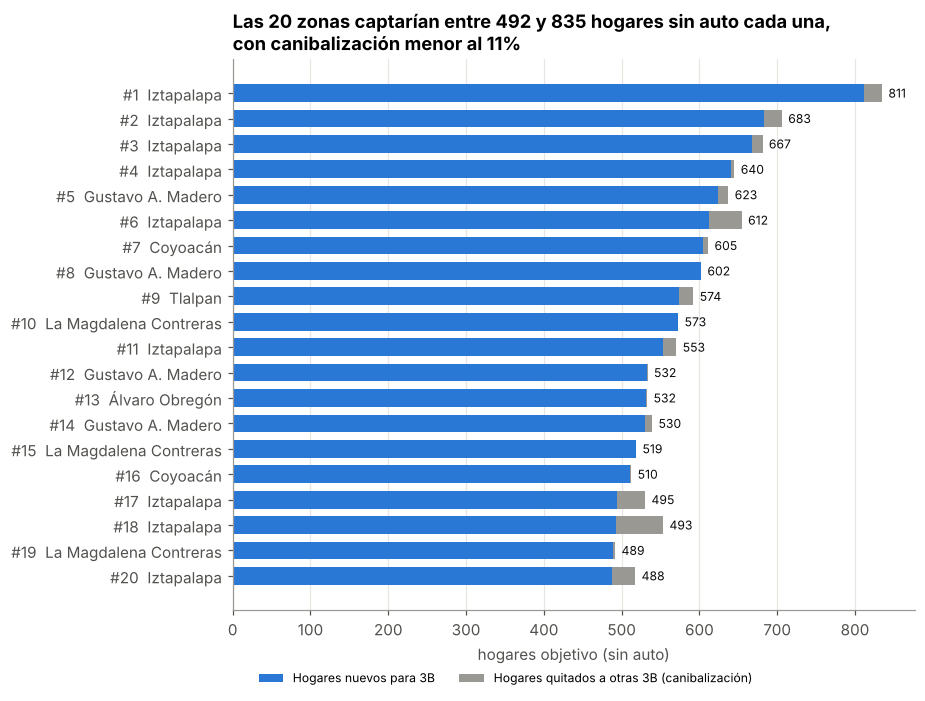

,posicion,h3,alcaldia,indice_final,indice,factor_red,capturada,canibalizacion,pct_canibalizacion,hogares,hogares_sin_auto,pct_sin_auto,cuota_3b_actual,dist_3b_m,n_hard_discount,n_conveniencia,n_supermercado,n_tradicional,score
0,1,8949958ea2fffff,Iztapalapa,811.1,811.1,1.0,835.0,23.9,2.9,1206.0,900.00,74.63,0.000,1314.0,0,0,0,14,100.0
1,2,8949958cc83ffff,Iztapalapa,683.2,683.2,1.0,706.2,23.1,3.3,193.0,149.98,77.71,0.000,1560.0,0,0,0,5,99.9
2,3,8949958ea67ffff,Iztapalapa,667.2,667.2,1.0,681.3,14.0,2.1,558.0,454.61,81.47,0.000,1122.0,0,0,0,8,99.9
3,4,8949958ea3bffff,Iztapalapa,640.0,640.0,1.0,645.2,5.1,0.8,1060.0,707.88,66.78,0.000,1303.0,0,0,0,30,99.8
4,5,894995aa2bbffff,Gustavo A. Madero,623.4,623.4,1.0,637.4,14.0,2.2,948.0,701.60,74.01,0.000,1288.0,0,0,0,22,99.8
5,6,8949958eb4bffff,Iztapalapa,611.9,611.9,1.0,654.6,42.6,6.5,695.0,429.76,61.84,0.038,940.0,0,0,0,8,99.8
6,7,894995853b3ffff,Coyoacán,605.0,605.0,1.0,611.4,6.4,1.0,682.0,329.92,48.38,0.000,1710.0,0,0,0,8,99.8
7,8,894995b963bffff,Gustavo A. Madero,602.3,602.3,1.0,602.3,0.0,0.0,635.0,296.04,46.62,0.000,2209.0,0,0,0,7,99.7
8,9,894995845d7ffff,Tlalpan,573.7,573.7,1.0,592.4,18.7,3.2,1179.0,688.62,58.41,0.000,1362.0,0,0,0,14,99.6
9,10,894995b34d3ffff,La Magdalena Contreras,572.9,572.9,1.0,572.9,0.0,0.0,555.0,386.00,69.55,0.000,2115.0,0,0,0,9,99.6


In [3]:
t = top.sort_values("posicion", ascending=False)
etq = [f"#{p}  {a}" for p, a in zip(t.posicion, t.alcaldia)]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(etq, t.indice, color=AZUL, height=0.7, label="Hogares nuevos para 3B")
ax.barh(etq, t.canibalizacion, left=t.indice, color=GRIS, height=0.7, label="Hogares quitados a otras 3B (canibalización)")
for i, (v, cap) in enumerate(zip(t.indice_final, t.capturada)):
    ax.text(cap + 8, i, f"{v:,.0f}", va="center", fontsize=8, color=TINTA)
ax.set_xlabel("hogares objetivo (sin auto)"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.09), ncol=2, fontsize=8)
ax.set_title(f"Las 20 zonas captarían entre {top.capturada.min():,.0f} y {top.capturada.max():,.0f} hogares sin auto cada una,\n"
             f"con canibalización menor al {np.ceil(top.pct_canibalizacion.max()):.0f}%")
fig.savefig(FIG / "03_top20_composicion.png")
plt.show()
top[ih.COLUMNAS_TOP[:-2] if "lat" not in top else ih.COLUMNAS_TOP].head(20)

## 3. Por qué un Huff **anidado**

En el Huff simple, 3B es "una tienda más" entre ~39 mil tienditas: el modelo cree que una 3B nueva a una cuadra de otra casi no la afecta.
En el anidado, el hogar elige primero el **tipo** de tienda (descuento, conveniencia, súper, tradicional) y luego la tienda: una 3B nueva compite sobre todo con otras tiendas de descuento.

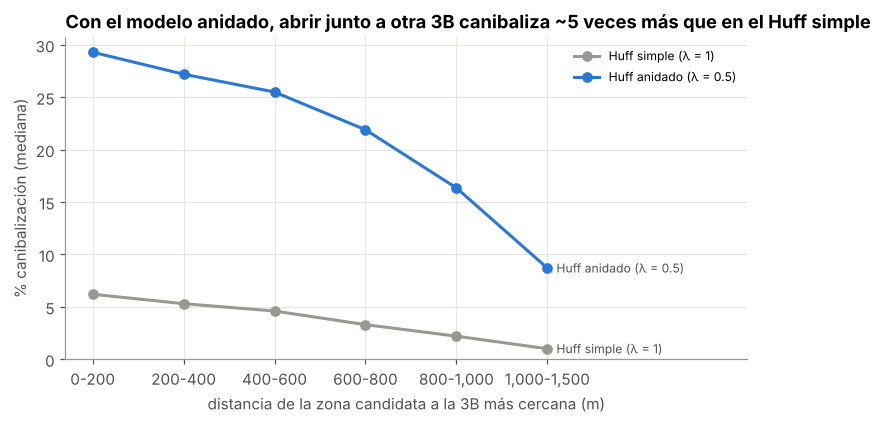

,Huff simple (λ = 1),Huff anidado (λ = 0.5)
0-200,6.2,29.3
200-400,5.3,27.2
400-600,4.6,25.5
600-800,3.3,21.9
"800-1,000",2.2,16.4
"1,000-1,500",1.0,8.7


In [4]:
m, dem = ih.preparar_demanda()
of = ih.oferta_por_hexagono(est.to_crs(cfg.CRS_WEB))
pares = ih.pares_cercanos(set(dem.h3) | set(of.h3))
dist = ih.distancia_a_3b(dem, est)
bandas = [0, 200, 400, 600, 800, 1000, 1500]
etiquetas = ["0-200", "200-400", "400-600", "600-800", "800-1,000", "1,000-1,500"]
curvas = {}
for lam, nombre in [(1.0, "Huff simple (λ = 1)"), (cfg.HUFF_LAMBDA_NIDO, f"Huff anidado (λ = {cfg.HUFF_LAMBDA_NIDO})")]:
    r = ih.calcular_indice(dem, of, pares, lam=lam)
    curvas[nombre] = r.groupby(pd.cut(dist, bandas, labels=etiquetas), observed=True)["pct_canibalizacion"].median()

fig, ax = plt.subplots(figsize=(8, 3.8))
for (nombre, s), col in zip(curvas.items(), [GRIS, AZUL]):
    ax.plot(range(len(s)), s.values, marker="o", color=col, linewidth=2, markersize=6, label=nombre)
    ax.text(len(s) - 1 + 0.1, s.values[-1], nombre, va="center", fontsize=8, color=TINTA2)
ax.set_xticks(range(len(etiquetas)), etiquetas)
ax.set_xlabel("distancia de la zona candidata a la 3B más cercana (m)"); ax.set_ylabel("% canibalización (mediana)")
ax.set_xlim(-0.3, len(etiquetas) + 1.2); ax.set_ylim(0, None)
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Con el modelo anidado, abrir junto a otra 3B canibaliza ~5 veces más que en el Huff simple")
fig.savefig(FIG / "03_huff_simple_vs_anidado.png")
plt.show()
pd.DataFrame(curvas).round(1)

## 4. KDE clásico vs índice H3 (comparación pedida)

El **KDE** suaviza la demanda en una superficie continua: muestra dónde vive el cliente objetivo.
El **índice H3** parte de la misma demanda pero resta lo que ya captan la competencia y las propias 3B: muestra dónde **falta** una 3B.

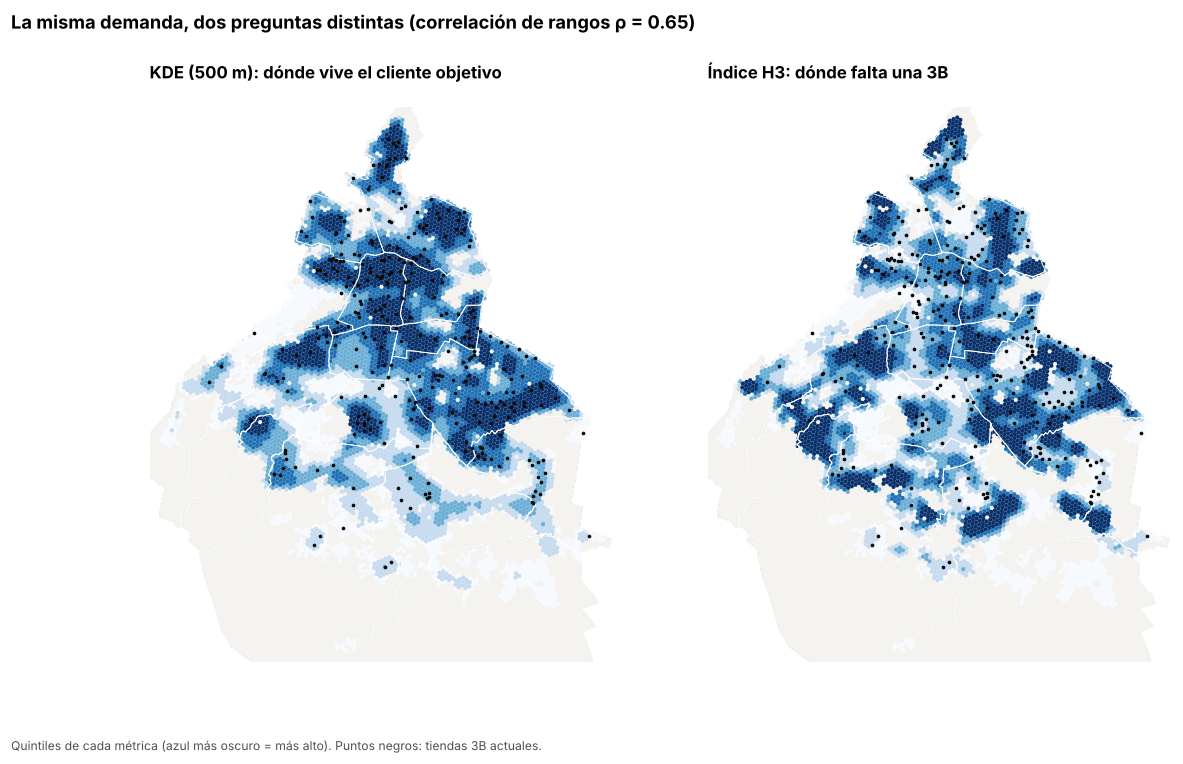

In [5]:
from scipy.stats import spearmanr
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, col, titulo in [(axes[0], "kde_500", "KDE (500 m): dónde vive el cliente objetivo"),
                        (axes[1], "indice_final", "Índice H3: dónde falta una 3B")]:
    base(ax)
    indice.plot(ax=ax, column=col, cmap="Blues", scheme="quantiles", k=5, linewidth=0)
    alc.boundary.plot(ax=ax, color="white", linewidth=0.6)
    tiendas_3b.plot(ax=ax, color=TINTA, markersize=2, zorder=3)
    ax.set_title(titulo, fontsize=11)
rho = spearmanr(indice.kde_500, indice.indice_final).statistic
fig.suptitle(f"La misma demanda, dos preguntas distintas (correlación de rangos ρ = {rho:.2f})",
             x=0.02, ha="left", fontweight="bold", fontsize=12)
fig.text(0.02, 0.02, "Quintiles de cada métrica (azul más oscuro = más alto). Puntos negros: tiendas 3B actuales.", fontsize=8, color=TINTA2)
fig.savefig(FIG / "03_kde_vs_h3.png")
plt.show()

## 5. Lectura para negocio

| Hallazgo | Implicación para 3B |
| --- | --- |
| Iztapalapa y GAM concentran la mayoría del Top 20 | Las zonas de mayor densidad y menor tasa de autos siguen sin cubrir dentro de la red actual |
| Las zonas recomendadas están a 0.7–2.2 km de la 3B más cercana | Son huecos dentro del radio logístico: abrir ahí no exige nueva infraestructura |
| La canibalización del Top 20 es < 11% | Cada apertura suma clientes nuevos en lugar de redistribuir los existentes |
| KDE e índice coinciden solo parcialmente (ρ ≈ 0.5) | Un mapa de calor de población sobreestima zonas ya atendidas: hace falta modelar competencia |

**Siguiente paso (Fase 4):** construir el índice con el corte 2021 y medir si anticipa las 162 aperturas reales 2021→2026.